# RouteRanker – Milestone 2: Exploratory Data Analysis and Data Processing

**Project:** AI-Powered Public Transit Route Optimization  
**City:** New York, USA  
**Transport Network:** New York MTA  
**Milestone:** 2 – Weeks 3–4

## 1. Introduction

Exploratory Data Analysis (EDA) is an important step in understanding transportation data. It helps identify patterns, trends, relationships and possible inefficiencies in public transit networks.

This milestone focuses on analyzing New York MTA route information, scheduled service patterns and passenger ridership data.

## 2. Objectives

- Analyze route usage and scheduled service patterns.
- Identify peak travel hours using available ridership data.
- Visualize stop and route distribution.
- Examine possible overlapping and low-service routes.
- Apply data preprocessing techniques.
- Prepare datasets for future machine learning models.

## 3. Scope

This notebook covers exploratory data analysis, data visualization, feature preprocessing, categorical encoding, feature scaling and preparation of training and validation datasets.

## 4. Data Sources

- New York MTA GTFS static feed.
- New York MTA Bus Hourly Ridership dataset.
- Processed route-level features generated during Milestone 1.

## 5. Expected Outcomes

- Understand route and service patterns.
- Identify high-demand periods using passenger ridership data.
- Generate meaningful visualizations.
- Prepare clean and structured datasets for machine learning.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("All required libraries imported successfully!")

All required libraries imported successfully!


## 6. Loading the Processed New York Route Dataset

### Introduction
The processed route-level dataset generated during Milestone 1 is loaded into this notebook for further exploratory analysis.

### Objective
To examine route-level features such as scheduled trip frequency, unique stops and average stops per trip.

In [2]:
# Upload the processed route-level dataset

from google.colab import files

uploaded = files.upload()

Saving new_york_route_features.csv to new_york_route_features.csv


In [3]:
# Load the uploaded dataset

import io

route_df = pd.read_csv(
    io.BytesIO(uploaded["new_york_route_features.csv"])
)

print("Dataset loaded successfully!")
print("Dataset Shape:", route_df.shape)

display(route_df.head())

Dataset loaded successfully!
Dataset Shape: (29, 14)


,agency_id,route_id,route_short_name,route_long_name,route_type,route_desc,route_url,route_color,route_text_color,route_sort_order,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
0,MTA NYCT,1,1,Broadway - 7 Avenue Local,1,Trains operate between Van Cortlandt Park-242 ...,https://www.mta.info/schedules/subway/1-train,D82233,FFFFFF,20,4100,76,152362,37.161463
1,MTA NYCT,2,2,7 Avenue Express,1,"Trains operate between Wakefield-241 St, Bronx...",https://www.mta.info/schedules/subway/2-train,D82233,FFFFFF,21,3014,142,152422,50.571334
2,MTA NYCT,3,3,7 Avenue Express,1,"Trains operate between Harlem-148 St, Manhatta...",https://www.mta.info/schedules/subway/3-train,D82233,FFFFFF,22,3071,68,91880,29.918593
3,MTA NYCT,4,4,Lexington Avenue Express,1,"Trains operate daily between Woodlawn, Bronx, ...",https://www.mta.info/schedules/subway/4-train,009952,FFFFFF,23,3802,108,118633,31.202788
4,MTA NYCT,5,5,Lexington Avenue Express,1,"Weekdays daytime, most trains operate between ...",https://www.mta.info/schedules/subway/5-train,009952,FFFFFF,24,2573,101,62877,24.437233


## 7. Initial Dataset Inspection

This section examines the structure and contents of the processed New York route-level dataset. It checks the available columns, data types, missing values, duplicate records, and basic statistical information. This helps us understand the dataset before performing exploratory data analysis and preprocessing.

In [4]:
# Inspect dataset structure

print("Dataset Information:")
route_df.info()

print("\nMissing Values in Each Column:")
display(route_df.isnull().sum())

print("\nDuplicate Rows:")
print(route_df.duplicated().sum())

print("\nStatistical Summary:")
display(route_df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   agency_id                29 non-null     object 
 1   route_id                 29 non-null     object 
 2   route_short_name         29 non-null     object 
 3   route_long_name          29 non-null     object 
 4   route_type               29 non-null     int64  
 5   route_desc               29 non-null     object 
 6   route_url                29 non-null     object 
 7   route_color              29 non-null     object 
 8   route_text_color         29 non-null     object 
 9   route_sort_order         29 non-null     int64  
 10  total_scheduled_trips    29 non-null     int64  
 11  unique_stops             29 non-null     int64  
 12  total_stop_time_records  29 non-null     int64  
 13  average_stops_per_trip   29 non-null     float64
dtypes: floa

,0
agency_id,0
route_id,0
route_short_name,0
route_long_name,0
route_type,0
route_desc,0
route_url,0
route_color,0
route_text_color,0
route_sort_order,0



Duplicate Rows:
0

Statistical Summary:


,agency_id,route_id,route_short_name,route_long_name,route_type,route_desc,route_url,route_color,route_text_color,route_sort_order,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
count,29,29,29,29,29.000000,29,29,29,29,29.000000,29.000000,29.000000,29.000000,29.000000
unique,1,29,27,23,NaN,29,25,10,2,NaN,NaN,NaN,NaN,NaN
top,MTA NYCT,1,S,Broadway Local,NaN,Trains operate between Van Cortlandt Park-242 ...,https://www.mta.info/schedules/subway/7-train,EB6800,FFFFFF,NaN,NaN,NaN,NaN,NaN
freq,29,1,3,3,NaN,1,2,5,25,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,1.034483,NaN,NaN,NaN,NaN,15.000000,2497.827586,70.241379,73782.275862,27.425285
std,NaN,NaN,NaN,NaN,0.185695,NaN,NaN,NaN,NaN,8.514693,1507.287134,34.319565,53263.763927,11.635716
min,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,1.000000,20.000000,4.000000,780.000000,2.000000
25%,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,8.000000,1100.000000,44.000000,13874.000000,21.000000
50%,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,15.000000,2999.000000,74.000000,85350.000000,29.000000
75%,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,22.000000,3396.000000,91.000000,113810.000000,36.112854


## 8. Route-Level Feature Analysis

This section explores the route-level features to understand the structure and service distribution of the New York MTA bus network. We analyze scheduled trips, unique stops, stop-time records, and average stops per trip to identify differences between routes.

In [5]:
# Display the available route-level features

print("Available Columns:")
print(route_df.columns.tolist())

print("\nRoute-Level Dataset:")
display(route_df.head(10))

Available Columns:
['agency_id', 'route_id', 'route_short_name', 'route_long_name', 'route_type', 'route_desc', 'route_url', 'route_color', 'route_text_color', 'route_sort_order', 'total_scheduled_trips', 'unique_stops', 'total_stop_time_records', 'average_stops_per_trip']

Route-Level Dataset:


,agency_id,route_id,route_short_name,route_long_name,route_type,route_desc,route_url,route_color,route_text_color,route_sort_order,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
0,MTA NYCT,1,1,Broadway - 7 Avenue Local,1,Trains operate between Van Cortlandt Park-242 ...,https://www.mta.info/schedules/subway/1-train,D82233,FFFFFF,20,4100,76,152362,37.161463
1,MTA NYCT,2,2,7 Avenue Express,1,"Trains operate between Wakefield-241 St, Bronx...",https://www.mta.info/schedules/subway/2-train,D82233,FFFFFF,21,3014,142,152422,50.571334
2,MTA NYCT,3,3,7 Avenue Express,1,"Trains operate between Harlem-148 St, Manhatta...",https://www.mta.info/schedules/subway/3-train,D82233,FFFFFF,22,3071,68,91880,29.918593
3,MTA NYCT,4,4,Lexington Avenue Express,1,"Trains operate daily between Woodlawn, Bronx, ...",https://www.mta.info/schedules/subway/4-train,009952,FFFFFF,23,3802,108,118633,31.202788
4,MTA NYCT,5,5,Lexington Avenue Express,1,"Weekdays daytime, most trains operate between ...",https://www.mta.info/schedules/subway/5-train,009952,FFFFFF,24,2573,101,62877,24.437233
5,MTA NYCT,6,6,Lexington Avenue Local,1,"Local trains operate between Pelham Bay Park, ...",https://www.mta.info/schedules/subway/6-train,009952,FFFFFF,25,3952,76,142718,36.112854
6,MTA NYCT,6X,6X,Pelham Bay Park Express,1,Express trains operate between Pelham Bay Park...,https://www.mta.info/schedules/subway/6-train,009952,FFFFFF,26,456,58,13224,29.000000
7,MTA NYCT,7,7,Flushing Local,1,"Trains operate between Flushing-Main St, Queen...",https://www.mta.info/schedules/subway/7-train,9A38A1,FFFFFF,27,4736,44,98106,20.714949
8,MTA NYCT,7X,7X,Flushing Express,1,"Trains operate between Flushing-Main St, Queen...",https://www.mta.info/schedules/subway/7-train,9A38A1,FFFFFF,28,428,36,7131,16.661215
9,MTA NYCT,A,A,8 Avenue Express,1,"Trains operate between Inwood-207 St, Manhatta...",https://www.mta.info/schedules/subway/a-train,0062CF,FFFFFF,1,3401,131,113810,33.463687


## 9. Scheduled Trips by Route

This visualization compares the number of scheduled trips across different New York MTA bus routes. It helps identify routes with higher and lower scheduled service levels.

**Note:** Scheduled trip counts represent planned service frequency, not actual passenger ridership.

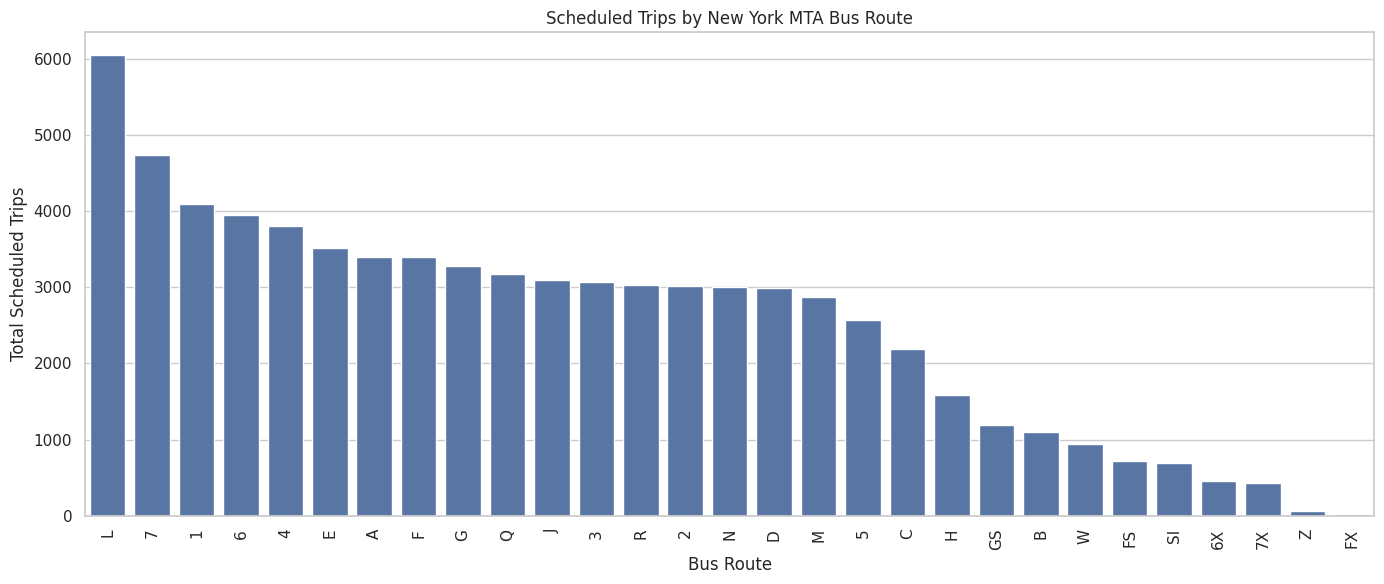

In [9]:
# Visualize scheduled trips by route

plt.figure(figsize=(14, 6))

sns.barplot(
    data=route_df.sort_values("total_scheduled_trips", ascending=False),
    x="route_id",
    y="total_scheduled_trips"
)

plt.title("Scheduled Trips by New York MTA Bus Route")
plt.xlabel("Bus Route")
plt.ylabel("Total Scheduled Trips")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 10. Unique Stops by Route

This section compares the number of unique stops served by each bus route. It helps us understand the geographical coverage of different routes and identify routes that serve more or fewer stops.

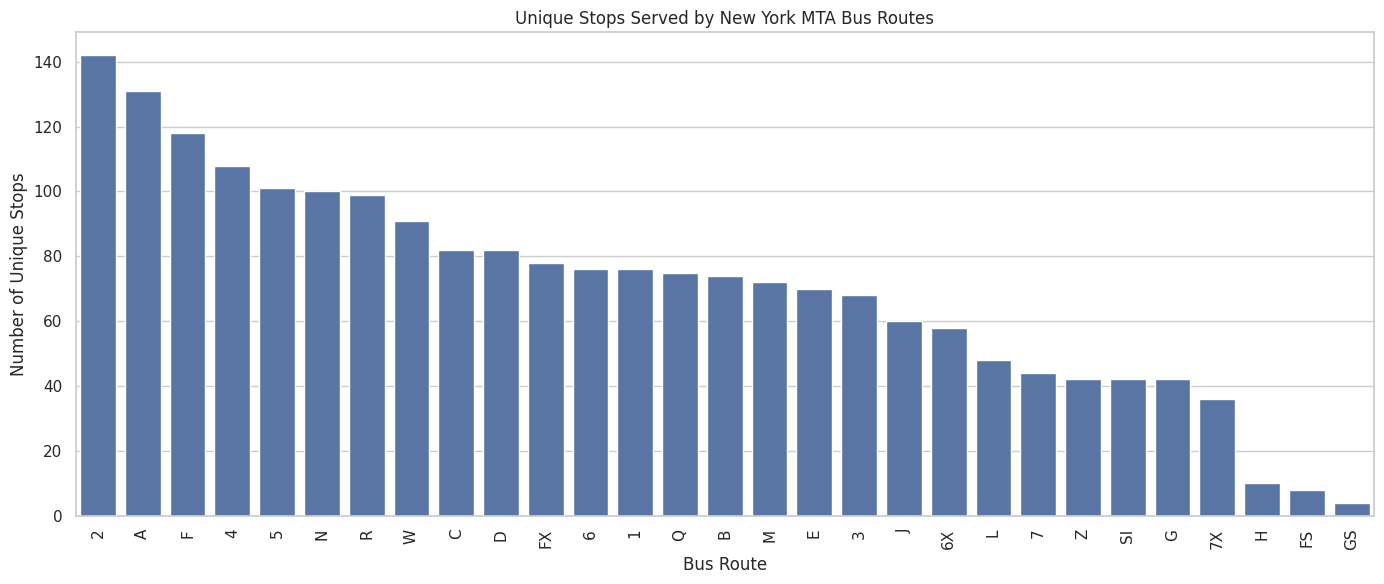

In [10]:
# Visualize unique stops by route

plt.figure(figsize=(14, 6))

sns.barplot(
    data=route_df.sort_values("unique_stops", ascending=False),
    x="route_id",
    y="unique_stops"
)

plt.title("Unique Stops Served by New York MTA Bus Routes")
plt.xlabel("Bus Route")
plt.ylabel("Number of Unique Stops")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 11. Average Stops per Trip Analysis

This section analyzes the average number of stops per trip across the New York MTA bus routes. The distribution helps us understand differences in route length and stop coverage. It also helps identify routes with relatively higher or lower average stop counts.

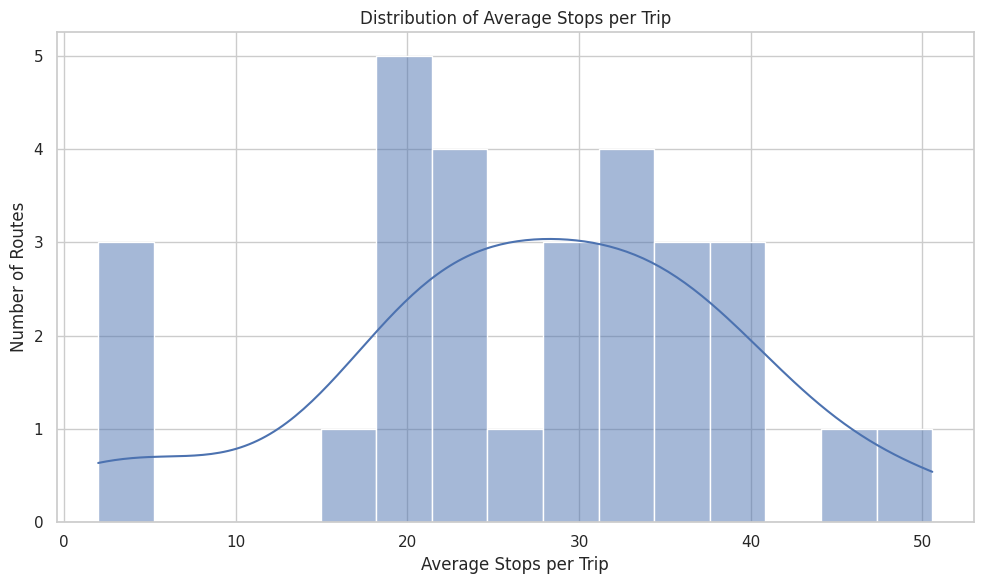

In [11]:
# Visualize the distribution of average stops per trip

plt.figure(figsize=(10, 6))

sns.histplot(
    data=route_df,
    x="average_stops_per_trip",
    bins=15,
    kde=True
)

plt.title("Distribution of Average Stops per Trip")
plt.xlabel("Average Stops per Trip")
plt.ylabel("Number of Routes")
plt.tight_layout()
plt.show()

## 12. Stop-Time Records by Route

This section compares the total number of stop-time records associated with each bus route. Stop-time records represent scheduled arrival and departure information at stops. This analysis helps us understand the scheduled service activity across different routes.

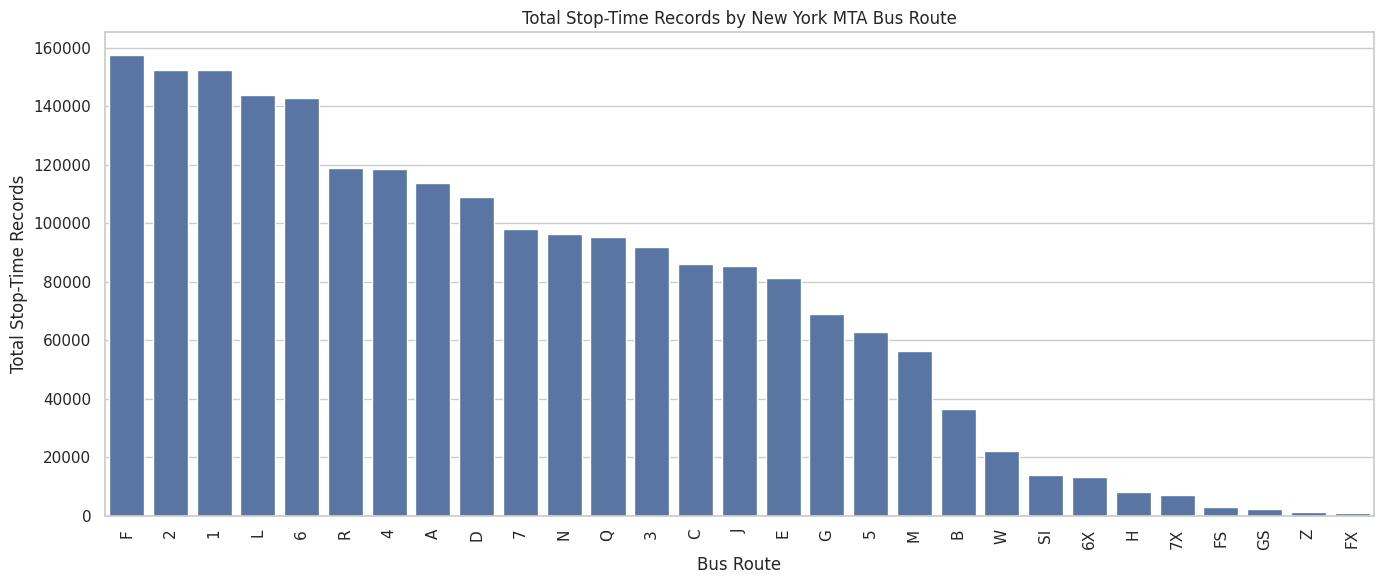

In [12]:
# Visualize total stop-time records by route

plt.figure(figsize=(14, 6))

sns.barplot(
    data=route_df.sort_values("total_stop_time_records", ascending=False),
    x="route_id",
    y="total_stop_time_records"
)

plt.title("Total Stop-Time Records by New York MTA Bus Route")
plt.xlabel("Bus Route")
plt.ylabel("Total Stop-Time Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 13. Relationship Between Scheduled Trips and Unique Stops

This section examines the relationship between the total scheduled trips and unique stops served by each bus route. A scatter plot is used to identify patterns between service frequency and route coverage. This helps us understand how scheduled service levels vary with the number of stops.

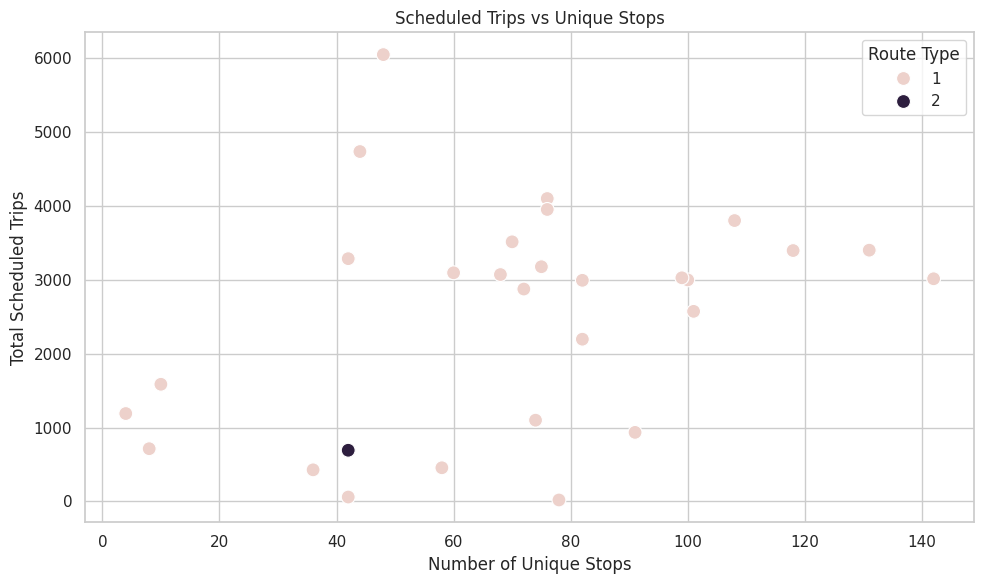

In [13]:
# Analyze the relationship between scheduled trips and unique stops

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=route_df,
    x="unique_stops",
    y="total_scheduled_trips",
    hue="route_type",
    s=100
)

plt.title("Scheduled Trips vs Unique Stops")
plt.xlabel("Number of Unique Stops")
plt.ylabel("Total Scheduled Trips")
plt.legend(title="Route Type")
plt.tight_layout()
plt.show()

## 14. Route-Level Statistical Summary

This section presents descriptive statistics for the numerical features in the dataset. It includes the mean, standard deviation, minimum, maximum, and quartile values. These statistics help us understand the distribution and variation of scheduled service features across bus routes.

In [14]:
# Generate statistical summary of route-level features

numerical_features = [
    "total_scheduled_trips",
    "unique_stops",
    "total_stop_time_records",
    "average_stops_per_trip"
]

display(route_df[numerical_features].describe().round(2))

,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
count,29.00,29.00,29.00,29.00
mean,2497.83,70.24,73782.28,27.43
std,1507.29,34.32,53263.76,11.64
min,20.00,4.00,780.00,2.00
25%,1100.00,44.00,13874.00,21.00
50%,2999.00,74.00,85350.00,29.00
75%,3396.00,91.00,113810.00,36.11
max,6048.00,142.00,157469.00,50.57


## 15. Feature Selection

Feature selection identifies the relevant numerical attributes required for machine-learning experiments. In this project, we select scheduled trips, unique stops, total stop-time records, and average stops per trip as route-level features.

These features describe scheduled service characteristics and route coverage. They will be used for feature scaling and further analysis.

In [15]:
# Select relevant numerical features

selected_features = [
    "total_scheduled_trips",
    "unique_stops",
    "total_stop_time_records",
    "average_stops_per_trip"
]

model_df = route_df[selected_features].copy()

print("Selected Features:")
display(model_df.head())

print("\nSelected Dataset Shape:", model_df.shape)

Selected Features:


,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
0,4100,76,152362,37.161463
1,3014,142,152422,50.571334
2,3071,68,91880,29.918593
3,3802,108,118633,31.202788
4,2573,101,62877,24.437233



Selected Dataset Shape: (29, 4)


## 16. Feature Scaling Using StandardScaler

Feature scaling is an important preprocessing technique in machine learning. The selected features have different numerical ranges. For example, scheduled trips and stop-time records may have larger values than average stops per trip.

StandardScaler transforms the numerical features so that each feature has a mean of approximately 0 and a standard deviation of approximately 1. This helps prevent features with larger numerical values from dominating distance-based machine-learning algorithms.

In [16]:
# Apply StandardScaler to the selected features

scaler = StandardScaler()

scaled_features = scaler.fit_transform(model_df)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=selected_features
)

print("Feature Scaling Completed Successfully!")
display(scaled_df.head())

print("\nScaled Feature Means:")
display(scaled_df.mean().round(4))

print("\nScaled Feature Standard Deviations:")
display(scaled_df.std(ddof=0).round(4))

Feature Scaling Completed Successfully!


,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
0,1.081766,0.170764,1.501408,0.851560
1,0.348513,2.127905,1.502554,2.024435
2,0.386998,-0.066465,0.345790,0.218074
3,0.880560,1.119681,0.856954,0.330394
4,0.050755,0.912105,-0.208365,-0.261345



Scaled Feature Means:


,0
total_scheduled_trips,-0.0
unique_stops,0.0
total_stop_time_records,-0.0
average_stops_per_trip,0.0



Scaled Feature Standard Deviations:


,0
total_scheduled_trips,1.0
unique_stops,1.0
total_stop_time_records,1.0
average_stops_per_trip,1.0


## 17. Training and Validation Dataset Split

Dataset splitting divides the processed data into separate training and validation sets. The training set is used to develop machine-learning models, while the validation set is used to evaluate their performance on data not used during training.

In this project, 80% of the route records are allocated for training and 20% for validation.

In [17]:
# Split the scaled dataset into training and validation sets

X_train, X_val = train_test_split(
    scaled_df,
    test_size=0.20,
    random_state=42
)

print("Dataset Splitting Completed!")

print("Original Dataset:", scaled_df.shape)
print("Training Dataset:", X_train.shape)
print("Validation Dataset:", X_val.shape)

Dataset Splitting Completed!
Original Dataset: (29, 4)
Training Dataset: (23, 4)
Validation Dataset: (6, 4)


## 18. Export Processed Datasets

After feature scaling and dataset splitting, the processed training and validation datasets are exported as CSV files. These files can be reused in future clustering and route optimization experiments without repeating the preprocessing steps.

In [18]:
# Export processed datasets

X_train.to_csv("new_york_train_scaled.csv", index=False)
X_val.to_csv("new_york_validation_scaled.csv", index=False)
scaled_df.to_csv("new_york_scaled_features.csv", index=False)

print("Processed datasets exported successfully!")

print("\nGenerated Files:")
print("1. new_york_train_scaled.csv")
print("2. new_york_validation_scaled.csv")
print("3. new_york_scaled_features.csv")

Processed datasets exported successfully!

Generated Files:
1. new_york_train_scaled.csv
2. new_york_validation_scaled.csv
3. new_york_scaled_features.csv


## 19. Correct Training and Validation Preprocessing

To avoid data leakage, the dataset is first divided into training and validation sets. StandardScaler is fitted only on the training data, and the same transformation is applied to the validation data.

This ensures that the validation dataset remains independent during preprocessing and provides a more reliable basis for future model evaluation.

In [19]:
# Split raw features before scaling

X_train_raw, X_val_raw = train_test_split(
    model_df,
    test_size=0.20,
    random_state=42
)

# Fit scaler only on training data
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=selected_features,
    index=X_train_raw.index
)

# Apply the same scaler to validation data
X_val = pd.DataFrame(
    scaler.transform(X_val_raw),
    columns=selected_features,
    index=X_val_raw.index
)

print("Correct preprocessing completed!")
print("Training dataset:", X_train.shape)
print("Validation dataset:", X_val.shape)

# Export corrected datasets
X_train.to_csv("new_york_train_scaled.csv", index=False)
X_val.to_csv("new_york_validation_scaled.csv", index=False)

print("\nCorrected CSV files exported successfully!")

Correct preprocessing completed!
Training dataset: (23, 4)
Validation dataset: (6, 4)

Corrected CSV files exported successfully!
